### Random Forest Classifier for Car Evaluation

In [2]:
# Import the libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report

In [3]:
# Load the dataset
cols=['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
df = pd.read_csv("./datasets/assignment-09.csv",header=None,names=cols)

df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [4]:
# Explore the dataset
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nClass distribution:")
print(df["class"].value_counts())

Dataset shape: (1728, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Missing values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Duplicate records: 0

Class distribution:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [5]:
# Define the features and target variable
X = df.drop('class',axis=1)
y=df['class']

print("Feature shape:",X.shape)
print("Target shape:",y.shape)

Feature shape: (1728, 6)
Target shape: (1728,)


In [6]:
# Train and test split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:",len(X_train))
print("Testing samples:",len(X_test))

Training samples: 1382
Testing samples: 346


In [7]:
# Encode categorical features
encoder = OneHotEncoder(handle_unknown='ignore')

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (1382, 21)
Encoded testing shape: (346, 21)


In [9]:
# Train the random forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train_encoded,y_train)

print("Random forest model trained successfully.")

Random forest model trained successfully.


In [10]:
# Make predictions on the test set
y_pred = model.predict(X_test_encoded)
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})

results.head(10)

,Actual,Predicted
0,good,good
1,unacc,unacc
2,unacc,unacc
3,unacc,unacc
4,acc,acc
5,unacc,unacc
6,unacc,unacc
7,acc,acc
8,unacc,unacc
9,unacc,unacc


In [11]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy

print("Accuracy",round(accuracy,4))
print("Error rate",round(error_rate,4))

print("\nClassification report:")
print(classification_report(y_test, y_pred,zero_division=0))

Accuracy 0.9682
Error rate 0.0318

Classification report:
              precision    recall  f1-score   support

         acc       0.94      0.96      0.95        77
        good       0.81      0.93      0.87        14
       unacc       0.99      0.99      0.99       242
       vgood       0.90      0.69      0.78        13

    accuracy                           0.97       346
   macro avg       0.91      0.89      0.90       346
weighted avg       0.97      0.97      0.97       346



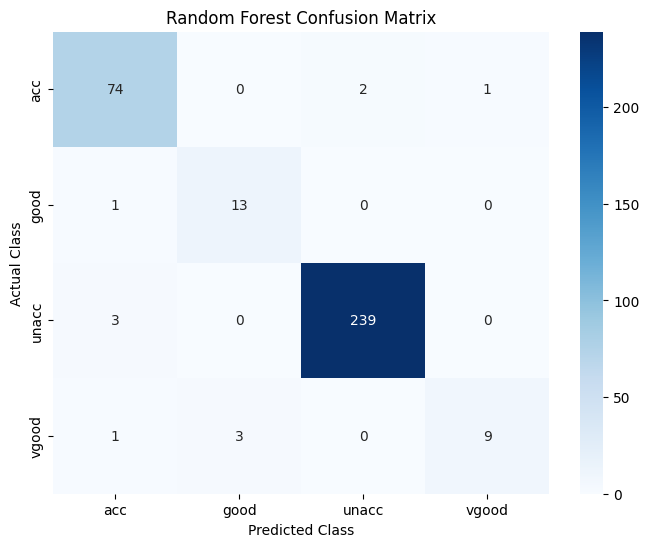

In [12]:
# Confusion matrix
labels=model.classes_
cm=confusion_matrix(y_test,y_pred,labels=labels)


plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

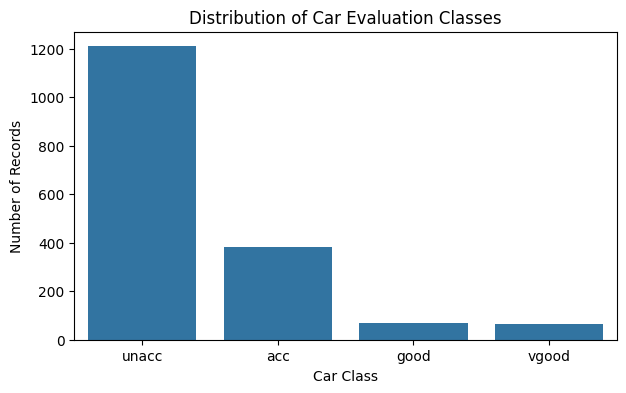

In [13]:
# Visualize class distribution

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="class", order=df["class"].value_counts().index)

plt.title("Distribution of Car Evaluation Classes")
plt.xlabel("Car Class")
plt.ylabel("Number of Records")
plt.show()

In [14]:
# Predict a new car configuration
new_car = pd.DataFrame([{
    "buying": "vhigh",
    "maint": "high",
    "doors": "4",
    "persons": "4",
    "lug_boot": "med",
    "safety": "high"
}])

new_car_encoded = encoder.transform(new_car)
prediction = model.predict(new_car_encoded)

print("Predicted car class:", prediction[0])

Predicted car class: unacc
